In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data=pd.read_csv("D:/Extract here/Hospital_Emergency_Analysis_Dataset_with_Nulls_Duplicates.csv")
data.head()     #first 5 records display hote hai

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome
0,ER00001,2025-02-13,21:24,94.0,Male,Nashik,Fracture,General Medicine,High,Ambulance,19.0,113.0,Admitted
1,ER00002,2025-04-08,02:59,72.0,Male,Nagpur,Diabetes Complication,Orthopedics,High,Referral,29.0,98.0,Transferred
2,ER00003,2025-11-10,20:58,8.0,Other,Chandrapur,High Blood Pressure,Neurology,Low,Walk-in,54.0,61.0,Transferred
3,ER00004,2025-04-14,16:48,63.0,Female,Nagpur,Fever,Neurology,Low,Referral,74.0,48.0,Admitted
4,ER00005,2025-08-13,23:40,NaN,Male,Pune,Fracture,Emergency Care,High,Ambulance,15.0,98.0,Transferred


#### Insepting

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Visit_ID                510 non-null    str    
 1   Visit_Date              510 non-null    str    
 2   Arrival_Time            510 non-null    str    
 3   Age                     505 non-null    float64
 4   Gender                  507 non-null    str    
 5   City                    506 non-null    str    
 6   Medical_Condition       507 non-null    str    
 7   Department              507 non-null    str    
 8   Triage_Level            510 non-null    str    
 9   Arrival_Mode            510 non-null    str    
 10  Waiting_Time_Minutes    506 non-null    float64
 11  Treatment_Time_Minutes  507 non-null    float64
 12  Visit_Outcome           507 non-null    str    
dtypes: float64(3), str(10)
memory usage: 51.9 KB


In [7]:
data.shape

(510, 13)

In [8]:
data.columns

Index(['Visit_ID', 'Visit_Date', 'Arrival_Time', 'Age', 'Gender', 'City',
       'Medical_Condition', 'Department', 'Triage_Level', 'Arrival_Mode',
       'Waiting_Time_Minutes', 'Treatment_Time_Minutes', 'Visit_Outcome'],
      dtype='str')

In [9]:
data.tail()     #last 5 records display hote hai

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome
505,ER00150,2025-08-29,03:12,35.0,Other,Amravati,Headache,General Medicine,Low,Walk-in,43.0,13.0,Discharged
506,ER00209,2025-11-01,16:38,79.0,Female,Nagpur,Diabetes Complication,Neurology,Low,Ambulance,62.0,38.0,Discharged
507,ER00268,2025-06-22,19:48,33.0,Female,Chandrapur,Injury,Neurology,Low,Walk-in,79.0,30.0,Admitted
508,ER00342,2025-05-29,22:04,71.0,Male,Nagpur,Diabetes Complication,Respiratory,Low,Referral,55.0,51.0,Transferred
509,ER00421,2025-04-08,14:48,89.0,Male,Nashik,Vomiting,Cardiology,Moderate,Referral,2.0,53.0,Transferred


In [10]:
data.describe()

,Age,Waiting_Time_Minutes,Treatment_Time_Minutes
count,505.000000,506.000000,507.000000
mean,48.431683,41.409091,67.428008
std,26.565130,22.304478,37.128612
min,1.000000,0.000000,5.000000
25%,26.000000,26.000000,41.000000
50%,47.000000,43.000000,62.000000
75%,71.000000,57.000000,87.000000
max,95.000000,89.000000,197.000000


#### Insepting
    1.510 records :0 to 509 indexing
    2.3 columns are float64 (columns_name) 10 str column (columns_name)
    3.13 columns are there
    4. 28 Null values
    5. Total memory 51.9 KB

#### Cleansing

In [11]:
data.isnull().sum()

Visit_ID                  0
Visit_Date                0
Arrival_Time              0
Age                       5
Gender                    3
City                      4
Medical_Condition         3
Department                3
Triage_Level              0
Arrival_Mode              0
Waiting_Time_Minutes      4
Treatment_Time_Minutes    3
Visit_Outcome             3
dtype: int64

In [12]:
data.duplicated().sum()

np.int64(10)

In [13]:
data[data.duplicated()]

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome
500,ER00003,2025-11-10,20:58,8.0,Other,Chandrapur,High Blood Pressure,Neurology,Low,Walk-in,54.0,61.0,Transferred
501,ER00019,2025-02-26,04:59,37.0,Female,Nagpur,Breathing Difficulty,Emergency Care,Moderate,Ambulance,32.0,65.0,Transferred
502,ER00043,2025-08-25,15:48,36.0,Male,Chandrapur,Abdominal Pain,General Medicine,Moderate,Ambulance,29.0,71.0,Transferred
503,ER00076,2025-01-23,07:38,31.0,Female,Chandrapur,Back Pain,Respiratory,Moderate,Referral,42.0,45.0,Discharged
504,ER00104,2025-07-07,00:48,34.0,Female,Nagpur,High Blood Pressure,General Medicine,Moderate,Walk-in,39.0,83.0,Transferred
505,ER00150,2025-08-29,03:12,35.0,Other,Amravati,Headache,General Medicine,Low,Walk-in,43.0,13.0,Discharged
506,ER00209,2025-11-01,16:38,79.0,Female,Nagpur,Diabetes Complication,Neurology,Low,Ambulance,62.0,38.0,Discharged
507,ER00268,2025-06-22,19:48,33.0,Female,Chandrapur,Injury,Neurology,Low,Walk-in,79.0,30.0,Admitted
508,ER00342,2025-05-29,22:04,71.0,Male,Nagpur,Diabetes Complication,Respiratory,Low,Referral,55.0,51.0,Transferred
509,ER00421,2025-04-08,14:48,89.0,Male,Nashik,Vomiting,Cardiology,Moderate,Referral,2.0,53.0,Transferred


In [14]:
data2=data.drop_duplicates()
data2.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Visit_ID                500 non-null    str    
 1   Visit_Date              500 non-null    str    
 2   Arrival_Time            500 non-null    str    
 3   Age                     495 non-null    float64
 4   Gender                  497 non-null    str    
 5   City                    496 non-null    str    
 6   Medical_Condition       497 non-null    str    
 7   Department              497 non-null    str    
 8   Triage_Level            500 non-null    str    
 9   Arrival_Mode            500 non-null    str    
 10  Waiting_Time_Minutes    496 non-null    float64
 11  Treatment_Time_Minutes  497 non-null    float64
 12  Visit_Outcome           497 non-null    str    
dtypes: float64(3), str(10)
memory usage: 50.9 KB


In [15]:
data2.duplicated().sum()    #Matlab ab dataset mein duplicate rows nahi hain.

np.int64(0)

In [16]:
data2.isnull().sum()

Visit_ID                  0
Visit_Date                0
Arrival_Time              0
Age                       5
Gender                    3
City                      4
Medical_Condition         3
Department                3
Triage_Level              0
Arrival_Mode              0
Waiting_Time_Minutes      4
Treatment_Time_Minutes    3
Visit_Outcome             3
dtype: int64

In [17]:
data3 = data2.dropna()     #null value remove karne ke liye

In [18]:
data3.isnull().sum()

Visit_ID                  0
Visit_Date                0
Arrival_Time              0
Age                       0
Gender                    0
City                      0
Medical_Condition         0
Department                0
Triage_Level              0
Arrival_Mode              0
Waiting_Time_Minutes      0
Treatment_Time_Minutes    0
Visit_Outcome             0
dtype: int64

In [19]:
data3.shape

(472, 13)

In [20]:
data3[data3['Age'] <= 0]    #  (Age check karo)errorneous check 

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome


In [21]:
data3[data3['Waiting_Time_Minutes'] < 0]    #Waiting Time check karo

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome


In [22]:
data3[data3['Treatment_Time_Minutes'] < 0]   #Treatment Time check karo

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome


In [23]:
data3['Visit_ID'].duplicated().sum()  #Duplicate Visit_ID check karo

np.int64(0)

In [24]:
data3['Gender'].unique()                   #Unique values check karo
data3['Department'].unique()
data3['Medical_Condition'].unique()

<StringArray>
[             'Fracture', 'Diabetes Complication',   'High Blood Pressure',
                 'Fever',            'Chest Pain',     'Allergic Reaction',
             'Back Pain',        'Abdominal Pain',  'Breathing Difficulty',
              'Vomiting',                'Injury',              'Headache']
Length: 12, dtype: str

In [25]:
data3.describe()

,Age,Waiting_Time_Minutes,Treatment_Time_Minutes
count,472.000000,472.000000,472.000000
mean,48.904661,41.144068,67.976695
std,26.799670,22.469711,36.638150
min,1.000000,0.000000,5.000000
25%,26.000000,25.000000,42.000000
50%,50.000000,43.000000,63.500000
75%,71.250000,57.000000,87.250000
max,95.000000,88.000000,197.000000


In [26]:
data3['Gender'].value_counts()
data3['Department'].value_counts()
data3['Medical_Condition'].value_counts()
data3['Visit_Outcome'].value_counts()

Visit_Outcome
Discharged     163
Transferred    156
Admitted       153
Name: count, dtype: int64

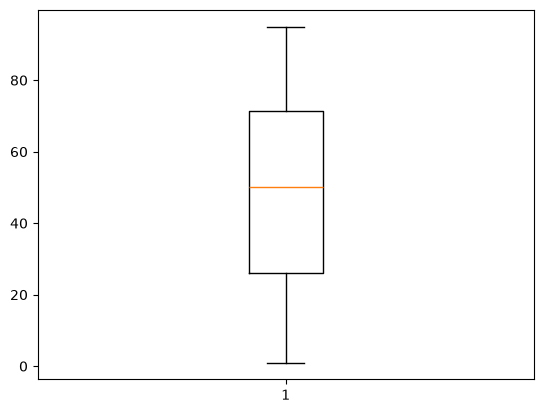

In [27]:
plt.boxplot(x=data3['Age'])
plt.show()

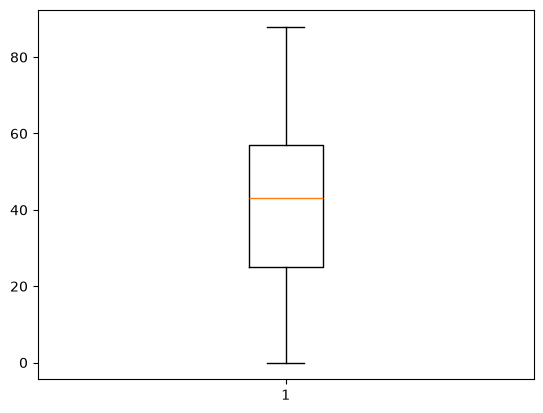

In [28]:
plt.boxplot(x=data3['Waiting_Time_Minutes'])
plt.show()

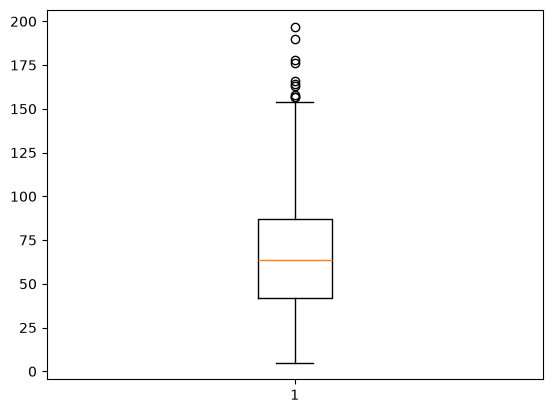

In [29]:
plt.boxplot(x=data3['Treatment_Time_Minutes'])
plt.show()

In [30]:
q3=data['Treatment_Time_Minutes'].quantile(0.75)
q1=data['Treatment_Time_Minutes'].quantile(0.25)

In [31]:
iqr=q3-q1

In [32]:
lb= q1 - 1.5 *iqr
ub= q3 + 1.5 * iqr

In [43]:
data3[data3['Treatment_Time_Minutes']<lb]

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome


In [44]:
data3[data3['Treatment_Time_Minutes']>ub]

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome
39,ER00040,2025-02-04,14:40,79.0,Male,Pune,Back Pain,Orthopedics,Critical,Walk-in,0.0,163.0,Transferred
144,ER00145,2025-10-27,22:49,92.0,Other,Chandrapur,Chest Pain,Emergency Care,High,Referral,21.0,157.0,Transferred
207,ER00208,2025-07-30,16:41,74.0,Female,Mumbai,Fracture,Cardiology,Critical,Walk-in,6.0,197.0,Admitted
217,ER00218,2025-01-01,14:17,50.0,Male,Chandrapur,Breathing Difficulty,Emergency Care,Critical,Referral,0.0,166.0,Transferred
221,ER00222,2025-08-21,17:11,29.0,Other,Mumbai,Fracture,General Medicine,Critical,Walk-in,13.0,190.0,Transferred
247,ER00248,2025-11-14,03:00,62.0,Other,Nagpur,Headache,Respiratory,Critical,Walk-in,11.0,178.0,Admitted
318,ER00319,2025-09-02,06:27,37.0,Male,Nagpur,Fever,Cardiology,Critical,Walk-in,0.0,158.0,Admitted
389,ER00390,2025-06-04,05:11,44.0,Other,Chandrapur,Abdominal Pain,Emergency Care,Critical,Ambulance,7.0,164.0,Discharged
447,ER00448,2025-03-21,14:59,39.0,Male,Chandrapur,Breathing Difficulty,Cardiology,Critical,Ambulance,0.0,157.0,Transferred
495,ER00496,2025-07-15,13:11,20.0,Female,Pune,Chest Pain,Orthopedics,Critical,Walk-in,4.0,176.0,Discharged


In [45]:
data3[(data3['Treatment_Time_Minutes']<lb) | (data3['Treatment_Time_Minutes']>ub)]

,Visit_ID,Visit_Date,Arrival_Time,Age,Gender,City,Medical_Condition,Department,Triage_Level,Arrival_Mode,Waiting_Time_Minutes,Treatment_Time_Minutes,Visit_Outcome
39,ER00040,2025-02-04,14:40,79.0,Male,Pune,Back Pain,Orthopedics,Critical,Walk-in,0.0,163.0,Transferred
144,ER00145,2025-10-27,22:49,92.0,Other,Chandrapur,Chest Pain,Emergency Care,High,Referral,21.0,157.0,Transferred
207,ER00208,2025-07-30,16:41,74.0,Female,Mumbai,Fracture,Cardiology,Critical,Walk-in,6.0,197.0,Admitted
217,ER00218,2025-01-01,14:17,50.0,Male,Chandrapur,Breathing Difficulty,Emergency Care,Critical,Referral,0.0,166.0,Transferred
221,ER00222,2025-08-21,17:11,29.0,Other,Mumbai,Fracture,General Medicine,Critical,Walk-in,13.0,190.0,Transferred
247,ER00248,2025-11-14,03:00,62.0,Other,Nagpur,Headache,Respiratory,Critical,Walk-in,11.0,178.0,Admitted
318,ER00319,2025-09-02,06:27,37.0,Male,Nagpur,Fever,Cardiology,Critical,Walk-in,0.0,158.0,Admitted
389,ER00390,2025-06-04,05:11,44.0,Other,Chandrapur,Abdominal Pain,Emergency Care,Critical,Ambulance,7.0,164.0,Discharged
447,ER00448,2025-03-21,14:59,39.0,Male,Chandrapur,Breathing Difficulty,Cardiology,Critical,Ambulance,0.0,157.0,Transferred
495,ER00496,2025-07-15,13:11,20.0,Female,Pune,Chest Pain,Orthopedics,Critical,Walk-in,4.0,176.0,Discharged


In [46]:
data3.loc[data3['Treatment_Time_Minutes']> ub,'Treatment_Time_Minutes']=ub

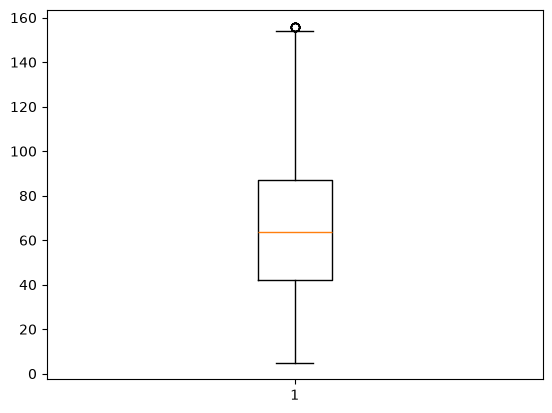

In [48]:
plt.boxplot(data3['Treatment_Time_Minutes'])
plt.show()

In [52]:
median=data['Treatment_Time_Minutes'].median()
data['Treatment_Time_Minutes'].fillna(median)

0      113.0
1       98.0
2       61.0
3       48.0
4       98.0
       ...  
505     13.0
506     38.0
507     30.0
508     51.0
509     53.0
Name: Treatment_Time_Minutes, Length: 510, dtype: float64

In [53]:
median=data['Treatment_Time_Minutes'].median()
data['Treatment_Time_Minutes']=data['Treatment_Time_Minutes'].fillna(median)

#### Univariate analysis

<Axes: xlabel='Treatment_Time_Minutes', ylabel='Count'>

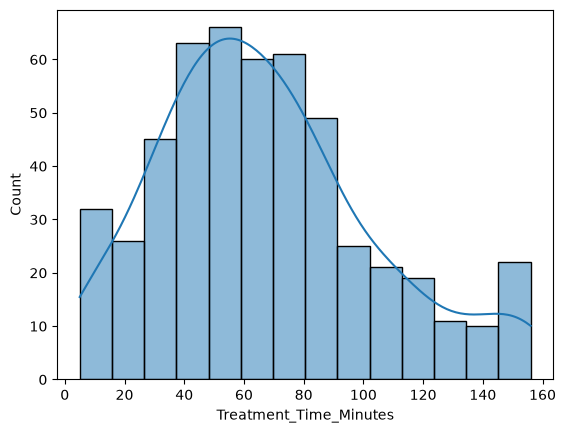

In [54]:
sns.histplot(data=data,x='Treatment_Time_Minutes',kde=True)

#### Bivariate analysis

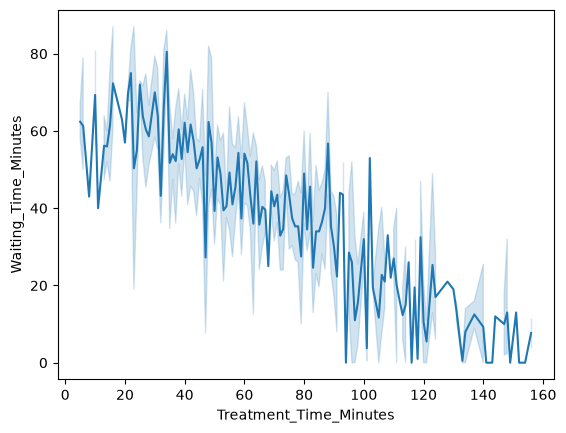

In [56]:
sns.lineplot(data, x='Treatment_Time_Minutes',y='Waiting_Time_Minutes')
plt.show()

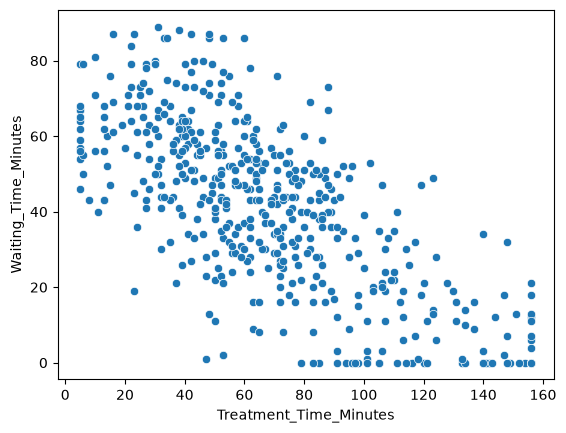

In [57]:
sns.scatterplot(data, x='Treatment_Time_Minutes',y='Waiting_Time_Minutes')
plt.show()

#### Multivariate analysis

In [58]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Visit_ID                510 non-null    str    
 1   Visit_Date              510 non-null    str    
 2   Arrival_Time            510 non-null    str    
 3   Age                     505 non-null    float64
 4   Gender                  507 non-null    str    
 5   City                    506 non-null    str    
 6   Medical_Condition       507 non-null    str    
 7   Department              507 non-null    str    
 8   Triage_Level            510 non-null    str    
 9   Arrival_Mode            510 non-null    str    
 10  Waiting_Time_Minutes    506 non-null    float64
 11  Treatment_Time_Minutes  510 non-null    float64
 12  Visit_Outcome           507 non-null    str    
dtypes: float64(3), str(10)
memory usage: 51.9 KB


In [60]:
data3 = data[['Age', 'Waiting_Time_Minutes',
              'Treatment_Time_Minutes']]

In [61]:
data3.corr()

,Age,Waiting_Time_Minutes,Treatment_Time_Minutes
Age,1.000000,0.047851,-0.049037
Waiting_Time_Minutes,0.047851,1.000000,-0.708328
Treatment_Time_Minutes,-0.049037,-0.708328,1.000000


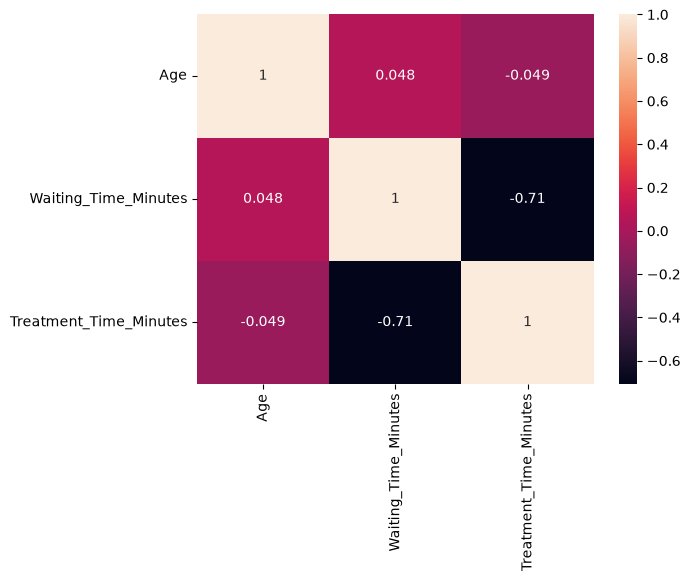

In [63]:
sns.heatmap(data3.corr(), annot=True)
plt.show()